# Week 5 - Task 3: Train & Visualize the Model
**Deep Learning & Neural Networks | AI Internship**

**Goal:** Train the Iris neural network for many epochs (100) and draw the accuracy and loss graphs to see how the model learns.

**Dataset:** Iris (UCI / scikit-learn), `iris.csv`

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
tf.keras.utils.set_random_seed(42)   # same results every time I run
os.makedirs("Screenshots", exist_ok=True)
import matplotlib.pyplot as plt
# small helper: saves printed text as a picture to use as a screenshot
def save_output_image(text, filename):
    lines = text.split("\n")
    fig = plt.figure(figsize=(10, 0.28*len(lines)+0.6))
    fig.text(0.02, 0.98, text, family="monospace", fontsize=9, va="top")
    fig.savefig(filename, dpi=130, bbox_inches="tight", facecolor="white")
    plt.close(fig)

I0000 00:00:1791714936.800339    3672 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791714938.188925    3672 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Load, preprocess and split the data (same steps as Task 2)

In [2]:
df = pd.read_csv("iris.csv")
X = df[["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]].values
encoder = LabelEncoder()
y = encoder.fit_transform(df["species"])      # setosa=0, versicolor=1, virginica=2
class_names = list(encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)       # fit only on training data
X_test = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


## Build the same neural network

In [3]:
def build_model():
    model = keras.Sequential([
        keras.Input(shape=(4,)),                 # input layer: 4 features
        layers.Dense(16, activation="relu"),     # hidden layer 1
        layers.Dense(8, activation="relu"),      # hidden layer 2
        layers.Dense(3, activation="softmax"),   # output layer: 3 species
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

## Train for 100 epochs
I use 20% of the training data as the validation set, so I can watch how the model behaves on data it is not training on.

In [4]:
history = model.fit(X_train, y_train, epochs=100, batch_size=8,
                    validation_split=0.2, verbose=0)

hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
hist.index.name = "epoch"
hist.to_csv("training_history.csv")
model.save("iris_ann.keras")
hist.iloc[[0, 1, 2, 4, 9, 19, 29, 49, 74, 99]].round(4)

,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.1562,1.2998,0.1667,1.2377
2,0.1979,1.1854,0.2500,1.1359
3,0.3021,1.0910,0.3333,1.0559
5,0.3750,0.9529,0.3750,0.9430
10,0.7500,0.7031,0.6250,0.7312
20,0.8333,0.4339,0.7083,0.5080
30,0.8542,0.3270,0.7917,0.3889
50,0.8750,0.2293,0.9167,0.2537
75,0.9688,0.1262,1.0000,0.0936


In [5]:
# training output screenshot (selected epochs)
rows = []
for e in [1, 2, 3, 5, 10, 20, 30, 50, 75, 100]:
    r = hist.loc[e]
    rows.append(f"Epoch {e:3d}/100 - loss: {r['loss']:.4f} - accuracy: {r['accuracy']:.4f} - val_loss: {r['val_loss']:.4f} - val_accuracy: {r['val_accuracy']:.4f}")
print("\n".join(rows))
save_output_image("TRAINING OUTPUT (selected epochs)\n" + "\n".join(rows), "Screenshots/01_training_output.png")

Epoch   1/100 - loss: 1.2998 - accuracy: 0.1562 - val_loss: 1.2377 - val_accuracy: 0.1667
Epoch   2/100 - loss: 1.1854 - accuracy: 0.1979 - val_loss: 1.1359 - val_accuracy: 0.2500
Epoch   3/100 - loss: 1.0910 - accuracy: 0.3021 - val_loss: 1.0559 - val_accuracy: 0.3333
Epoch   5/100 - loss: 0.9529 - accuracy: 0.3750 - val_loss: 0.9430 - val_accuracy: 0.3750
Epoch  10/100 - loss: 0.7031 - accuracy: 0.7500 - val_loss: 0.7312 - val_accuracy: 0.6250
Epoch  20/100 - loss: 0.4339 - accuracy: 0.8333 - val_loss: 0.5080 - val_accuracy: 0.7083
Epoch  30/100 - loss: 0.3270 - accuracy: 0.8542 - val_loss: 0.3889 - val_accuracy: 0.7917
Epoch  50/100 - loss: 0.2293 - accuracy: 0.8750 - val_loss: 0.2537 - val_accuracy: 0.9167
Epoch  75/100 - loss: 0.1262 - accuracy: 0.9688 - val_loss: 0.0936 - val_accuracy: 1.0000
Epoch 100/100 - loss: 0.0755 - accuracy: 0.9688 - val_loss: 0.0308 - val_accuracy: 1.0000


## Graph 1: Training Accuracy vs Validation Accuracy

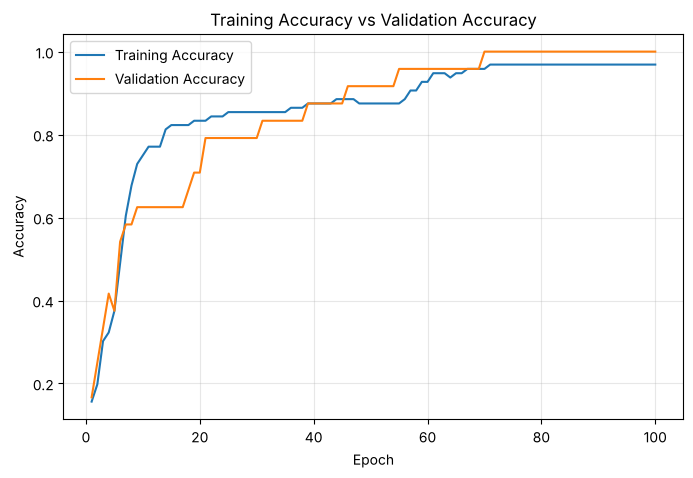

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(hist.index, hist["accuracy"], label="Training Accuracy", color="tab:blue")
plt.plot(hist.index, hist["val_accuracy"], label="Validation Accuracy", color="tab:orange")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("Screenshots/02_accuracy_graph.png", dpi=120, bbox_inches="tight")
plt.show()

## Graph 2: Training Loss vs Validation Loss

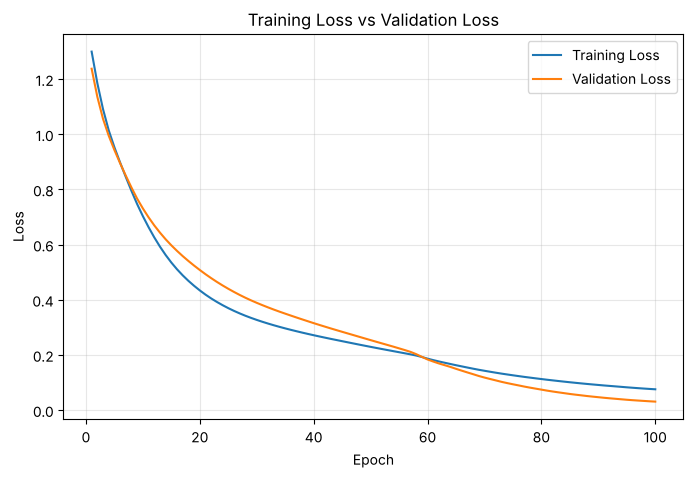

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(hist.index, hist["loss"], label="Training Loss", color="tab:blue")
plt.plot(hist.index, hist["val_loss"], label="Validation Loss", color="tab:orange")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("Screenshots/03_loss_graph.png", dpi=120, bbox_inches="tight")
plt.show()

In [8]:
# numbers I use in my explanation
print("Epoch 1   -> train acc: %.3f | val acc: %.3f | train loss: %.3f | val loss: %.3f" % tuple(hist.loc[1, ["accuracy","val_accuracy","loss","val_loss"]]))
print("Epoch 100 -> train acc: %.3f | val acc: %.3f | train loss: %.3f | val loss: %.3f" % tuple(hist.loc[100, ["accuracy","val_accuracy","loss","val_loss"]]))
print("Lowest validation loss: %.3f at epoch %d" % (hist["val_loss"].min(), hist["val_loss"].idxmin()))
print("Highest validation accuracy: %.3f at epoch %d" % (hist["val_accuracy"].max(), hist["val_accuracy"].idxmax()))

Epoch 1   -> train acc: 0.156 | val acc: 0.167 | train loss: 1.300 | val loss: 1.238
Epoch 100 -> train acc: 0.969 | val acc: 1.000 | train loss: 0.076 | val loss: 0.031
Lowest validation loss: 0.031 at epoch 100
Highest validation accuracy: 1.000 at epoch 70


## Explanation

**What happened to accuracy?** At epoch 1 the model was almost guessing, with training accuracy of only about 16%. It then rose steadily and reached about 97% on the training data and 100% on the validation data by epoch 100.

**What happened to loss?** Loss moved in the opposite direction. Training loss fell from about 1.30 to 0.08 and validation loss fell from about 1.24 to 0.03.

**Is the model improving?** Yes. Accuracy goes up and loss goes down together on both the training and validation data, so the model is learning real patterns.

**Is there any sign of overfitting?** I do not see a clear sign. Overfitting would show as training accuracy rising while validation loss starts to rise. Here the validation loss kept falling until the end. The validation accuracy is even higher than the training accuracy, which looks strange, but it happens because the validation set is tiny (only 24 flowers) and Keras averages the training accuracy over the whole epoch while the weights are still changing. Because the dataset is small, the curves are noisy, so next time I would use cross-validation.